# ボディ検査機 測定値トレンドレポート

指定した号機・検査項目・期間の測定値を、測定順に等間隔で表示します。

In [ ]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# ================================================
# Settings
# ================================================
DB_PATH = Path("../data/body_insp_measurement_data.db")

INSP_MACHINE_NO = 412
INSPECTION_ITEM = "total_length"
START_DATE = "2026-11-01"
END_DATE = "2026-11-30"

plt.rcParams["font.family"] = "Yu Gothic"


## 1. 測定データの取得

期間終了日の23:59:59まで含めるため、SQLでは翌日未満の条件を使用します。

In [2]:
if not DB_PATH.is_file():
    raise FileNotFoundError(f"DBファイルがありません: {DB_PATH}")

sql = """
SELECT measured_at, measured_value
FROM measurement_result
WHERE insp_machine_no = ?
  AND inspection_item = ?
  AND measured_at >= ?
  AND measured_at < ?
ORDER BY measured_at ASC
"""

end_exclusive = (
    pd.Timestamp(END_DATE) + pd.Timedelta(days=1)
).strftime("%Y-%m-%d")

with sqlite3.connect(DB_PATH) as conn:
    df = pd.read_sql_query(
        sql,
        conn,
        params=(INSP_MACHINE_NO, INSPECTION_ITEM, START_DATE, end_exclusive),
    )

print(f"DB: {DB_PATH}")
print(f"対象: {INSP_MACHINE_NO} / {INSPECTION_ITEM}")
print(f"期間: {START_DATE} ～ {END_DATE}")
print(f"データ件数: {len(df):,}件")
display(df.head(10))


DB: ..\data\body_insp_measurement_data.db
対象: 412 / total_length
期間: 2026-11-01 ～ 2026-11-30
データ件数: 360件


,measured_at,measured_value
0,2026-11-11 16:00:00,3.529
1,2026-11-11 16:00:30,3.514
2,2026-11-11 16:01:00,3.444
3,2026-11-11 16:01:31,3.429
4,2026-11-11 16:02:01,3.519
5,2026-11-11 16:02:31,3.486
6,2026-11-11 16:03:01,3.497
7,2026-11-11 16:03:32,3.441
8,2026-11-11 16:04:02,3.453
9,2026-11-11 16:04:32,3.477


## 2. 測定値の折れ線グラフ

横軸は日時ではなく測定順です。データ間の実際の時間差は反映しません。

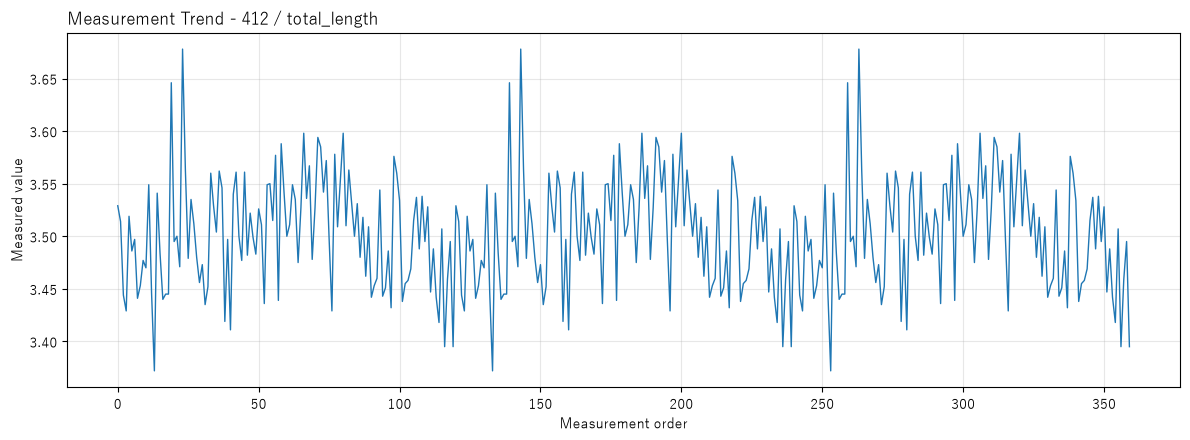

In [3]:
fig, ax = plt.subplots(figsize=(12, 4.5))

ax.plot(range(len(df)), df["measured_value"], linewidth=1)
ax.set_title(f"Measurement Trend - {INSP_MACHINE_NO} / {INSPECTION_ITEM}", loc="left")
ax.set_xlabel("Measurement order")
ax.set_ylabel("Measured value")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
